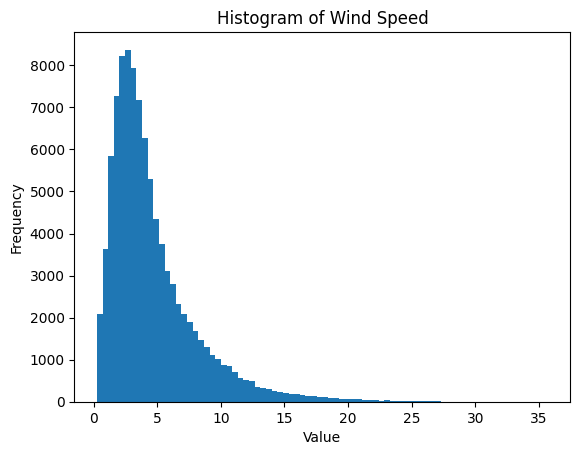

In [ ]:
# --------------------------------------------------
# Real Data Application
# --------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.special import betainc
from scipy.optimize import brentq

df = pd.read_csv("/content/sample_data/M2_wind_speed_2010_2020.csv")
df.head()
Wind_Speed_Obs = df["Avg Avg Wind Speed @ 80m [m/s]"] # select observation at 80m
Wind_Speed_Obs.shape

# Plot histogram
freq, bins, _ = plt.hist(Wind_Speed_Obs, bins=80)

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Histogram of Wind Speed")
plt.show()

In [ ]:

# Observed wind speed data
x = np.asarray(Wind_Speed_Obs)
n = len(x)

# Midpoint quantile levels: u_i = (i - 0.5) / n
u = (np.arange(1, n + 1) - 0.5) / n

# Empirical quantiles and their centered values
x_sorted = np.sort(x)
x_centered = x_sorted - np.mean(x)

# Centered W2 distance using matched quantiles
def centered_w2_distance(x_centered, q):
    q_centered = q - np.mean(q)
    return np.sqrt(np.mean((x_centered - q_centered) ** 2))


def quantile_corr(x_centered, q):
    q_centered = q - np.mean(q)
    return np.mean(x_centered * q_centered) / (
        np.std(x_centered, ddof=0) * np.std(q_centered, ddof=0)
    )


# --------------------------------------------------
# Basic CDFs
# --------------------------------------------------
def lindley_cdf(x, lam):
    return 1 - (1 + lam * x / (1 + lam)) * np.exp(-lam * x)


def generalized_lindley_cdf(x, alpha, lam):
    return lindley_cdf(x, lam) ** alpha


def beta_generated_cdf(G, a, b):
    return betainc(a, b, G)


# --------------------------------------------------
# Numerical inverse CDF (quantile function)
# --------------------------------------------------
def numerical_ppf(cdf, u, upper_start=0.1):
    q = []

    # Compute F^{-1}(u_i) for each quantile level u_i
    for ui in u:
        upper = upper_start

        # Increase the upper bound until F(upper) >= u_i so that the solution of F(z) = u_i is bracketed
        while cdf(upper) < ui:
            upper *= 2

        # Numerically solve F(z) = u_i on [0, upper]
        root = brentq(lambda z: cdf(z) - ui, 0, upper)
        q.append(root)

    return np.array(q)


# --------------------------------------------------
# 80 m parameters from your table
# --------------------------------------------------
params = {
    "BGL":  {"alpha": 25.281, "lam": 0.669, "a": 0.093, "b": 0.456},
    "BE":   {"lam": 0.882, "a": 3.279, "b": 0.353},
    "BW":   {"alpha": 0.463, "lam": 0.175, "a": 9.712, "b": 7.680},
    "BL":   {"lam": 1.415, "a": 2.894, "b": 0.241},
    "GEV":  {"lam": 1.941, "a": 2.945, "b": 0.245},
    "LogN": {"alpha": 1.285, "lam": 0.730},
    "GAM":  {"alpha": 2.158, "lam": 0.465},
    "GL":   {"alpha": 1.625, "lam": 0.472},
    "W":    {"alpha": 1.463, "lam": 0.194},
    "L":    {"lam": 0.373},
}


# --------------------------------------------------
# Quantile functions
# --------------------------------------------------

# Store theoretical quantiles for each fitted distribution
quantiles = {}

# Quantiles evaluated at the same levels u_i

# BGL
p = params["BGL"]
quantiles["BGL"] = numerical_ppf(
    lambda z: beta_generated_cdf(
        generalized_lindley_cdf(z, p["alpha"], p["lam"]),
        p["a"],
        p["b"]
    ),
    u
)

# BE
p = params["BE"]
quantiles["BE"] = numerical_ppf(
    lambda z: beta_generated_cdf(
        1 - np.exp(-p["lam"] * z),
        p["a"],
        p["b"]
    ),
    u
)

# BW
p = params["BW"]
quantiles["BW"] = numerical_ppf(
    lambda z: beta_generated_cdf(
        1 - np.exp(-(p["lam"] * z) ** p["alpha"]),
        p["a"],
        p["b"]
    ),
    u
)

# BL
p = params["BL"]
quantiles["BL"] = numerical_ppf(
    lambda z: beta_generated_cdf(
        lindley_cdf(z, p["lam"]),
        p["a"],
        p["b"]
    ),
    u
)

# GL
p = params["GL"]
quantiles["GL"] = numerical_ppf(
    lambda z: generalized_lindley_cdf(z, p["alpha"], p["lam"]),
    u
)

# L
p = params["L"]
quantiles["L"] = numerical_ppf(
    lambda z: lindley_cdf(z, p["lam"]),
    u
)

# Log-normal
p = params["LogN"]
quantiles["LogN"] = stats.lognorm.ppf(
    u,
    s=p["lam"],
    scale=np.exp(p["alpha"])
)

# Gamma
p = params["GAM"]
quantiles["GAM"] = stats.gamma.ppf(
    u,
    a=p["alpha"],
    scale=1 / p["lam"]
)

# Weibull
p = params["W"]
quantiles["W"] = stats.weibull_min.ppf(
    u,
    c=p["alpha"],
    scale=1 / p["lam"]
)

# GEV
p = params["GEV"]
quantiles["GEV"] = stats.genextreme.ppf(
    u,
    c=-p["b"],
    loc=p["a"],
    scale=p["lam"]
)


# --------------------------------------------------
# Compute centered W2 and quantile correlation
# --------------------------------------------------
for name, q in quantiles.items():
    w2c = centered_w2_distance(x_centered, q)
    qcorr = quantile_corr(x_centered, q)
    print(f"{name:5s}  centered W2 = {w2c:.4f}   quantile corr = {qcorr:.4f}")

BGL    centered W2 = 0.1030   quantile corr = 0.9996
BE     centered W2 = 0.2166   quantile corr = 0.9985
BW     centered W2 = 0.2194   quantile corr = 0.9980
BL     centered W2 = 0.2664   quantile corr = 0.9980
GL     centered W2 = 0.6102   quantile corr = 0.9907
L      centered W2 = 0.4467   quantile corr = 0.9946
LogN   centered W2 = 0.7525   quantile corr = 0.9879
GAM    centered W2 = 0.5183   quantile corr = 0.9923
W      centered W2 = 0.6236   quantile corr = 0.9851
GEV    centered W2 = 1.0862   quantile corr = 0.9662


In [ ]:
ground_truth_mean = np.mean(Wind_Speed_Obs)
ground_truth_std = np.std(Wind_Speed_Obs, ddof=0)

Centered_W_2 = []
Quantile_Corr = []
Model = []
prediction_std =[]
prediction_mean = []

for name, q in quantiles.items():

    w2c = centered_w2_distance(x_centered, q)
    qcorr = quantile_corr(x_centered, q)
    fitted_std = np.std(q, ddof=0)
    fitted_mean = np.mean(q)

    Model.append(name)
    Centered_W_2.append(w2c)
    Quantile_Corr.append(qcorr)
    prediction_std.append(fitted_std)
    prediction_mean.append(fitted_mean)

print(Model)
print(Centered_W_2)
print(Quantile_Corr)
print(prediction_std)
print(prediction_mean)
print(ground_truth_mean)
print(ground_truth_std)

['BGL', 'BE', 'BW', 'BL', 'GL', 'L', 'LogN', 'GAM', 'W', 'GEV']
[np.float64(0.10295439388314971), np.float64(0.21658246093220263), np.float64(0.21944380195018454), np.float64(0.2664355830496822), np.float64(0.6101610227614259), np.float64(0.4467057833605682), np.float64(0.7525226348882965), np.float64(0.5183274016177919), np.float64(0.6236161581051577), np.float64(1.0862295876270007)]
[np.float64(0.9995711135101635), np.float64(0.9985447861713994), np.float64(0.9980276386034963), np.float64(0.9980290914385029), np.float64(0.9907026947954289), np.float64(0.9946431445400598), np.float64(0.9878929358229569), np.float64(0.992265579147783), np.float64(0.9850923559692123), np.float64(0.9662229180608886)]
[np.float64(3.487983159603576), np.float64(3.3598377928604104), np.float64(3.4421291363922544), np.float64(3.3135408841468936), np.float64(3.05532375250304), np.float64(3.7207374659599664), np.float64(3.9567983652060965), np.float64(3.1590852450680957), np.float64(3.2434013882219856), np.flo

In [ ]:
# ============================================================
# Wasserstein target diagram coordinates
# ============================================================

# Signed centered Wasserstein distance
Signed_Centered_W_2 = (
    np.sign(np.array(prediction_std) - ground_truth_std)
    * np.array(Centered_W_2)
)

# Mean bias
Bias = np.array(prediction_mean) - ground_truth_mean

# Total W2 distance
W_2 = np.sqrt(Signed_Centered_W_2**2 + Bias**2)

print("Centered_W_2:", Centered_W_2)
print("prediction_std:", prediction_std)
print("ground_truth_std:", ground_truth_std)


# ============================================================
# Save results
# ============================================================

results = pd.DataFrame({
    "Model": Model,
    "prediction_std": prediction_std,
    "ground_truth_std": ground_truth_std,
    "Signed_Centered_W_2": Signed_Centered_W_2,
    "prediction_mean": prediction_mean,
    "ground_truth_mean": ground_truth_mean,
    "Bias": Bias,
    "W_2": W_2
})

results.to_csv("/content/sample_data/Wind_Wasserstein_Target_Diagram.csv", index=False)

print(results)




Centered_W_2: [np.float64(0.10295439388314971), np.float64(0.21658246093220263), np.float64(0.21944380195018454), np.float64(0.2664355830496822), np.float64(0.6101610227614259), np.float64(0.4467057833605682), np.float64(0.7525226348882965), np.float64(0.5183274016177919), np.float64(0.6236161581051577), np.float64(1.0862295876270007)]
prediction_std: [np.float64(3.487983159603576), np.float64(3.3598377928604104), np.float64(3.4421291363922544), np.float64(3.3135408841468936), np.float64(3.05532375250304), np.float64(3.7207374659599664), np.float64(3.9567983652060965), np.float64(3.1590852450680957), np.float64(3.2434013882219856), np.float64(3.9715416787612625)]
ground_truth_std: 3.4735970492867803
  Model  prediction_std  ground_truth_std  Signed_Centered_W_2  \
0   BGL        3.487983          3.473597             0.102954   
1    BE        3.359838          3.473597            -0.216582   
2    BW        3.442129          3.473597            -0.219444   
3    BL        3.313541    

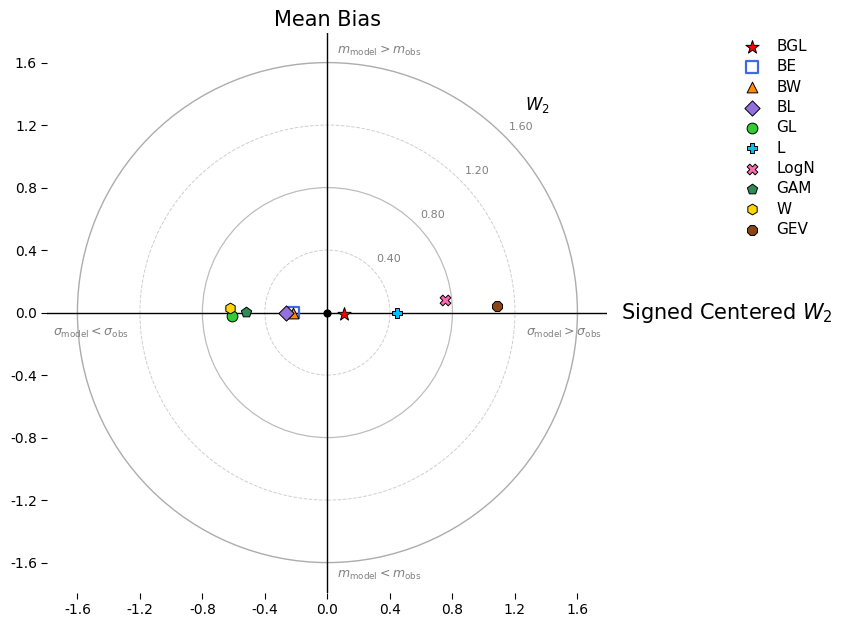

In [ ]:
# ============================================================
# Wasserstein Target Diagram
# ============================================================


fig, ax = plt.subplots(figsize=(8, 8))


# ------------------------------------------------------------
# Determine outer W2 radius
# Always use exactly four circles
# ------------------------------------------------------------

max_w2 = np.max(W_2)

if max_w2 <= 0.1:
    outer_step = 0.05
elif max_w2 <= 0.2:
    outer_step = 0.10
elif max_w2 <= 0.5:
    outer_step = 0.20
elif max_w2 <= 1.0:
    outer_step = 0.40
elif max_w2 <= 2.0:
    outer_step = 0.80
elif max_w2 <= 5.0:
    outer_step = 2.0
elif max_w2 <= 10.0:
    outer_step = 4.0
else:
    outer_step = 4.0

rmax = np.ceil(max_w2 / outer_step) * outer_step

# Exactly four equally spaced circles
radii = np.array([rmax / 4, rmax / 2, 3 * rmax / 4, rmax])


# ------------------------------------------------------------
# Draw exactly four W2 circles
# 1st dashed, 2nd solid, 3rd dashed, 4th solid
# ------------------------------------------------------------

circle_styles = [
    ("--", 0.7, 0.38),
    ("-", 0.9, 0.52),
    ("--", 0.7, 0.38),
    ("-", 1.0, 0.65)
]

for r, (linestyle, linewidth, alpha) in zip(radii, circle_styles):
    circle = plt.Circle((0, 0), r, fill=False, edgecolor="gray",
                        linewidth=linewidth, linestyle=linestyle,
                        alpha=alpha, zorder=0)
    ax.add_patch(circle)


# ------------------------------------------------------------
# Label W2 contours
# Label second and outer circles only
# ------------------------------------------------------------

theta = np.pi / 4

for i in [0,1,2,3]:
    r = radii[i]
    ax.text((r + 0.025 * rmax) * np.cos(theta),
            (r + 0.025 * rmax) * np.sin(theta),
            f"{r:.2f}", fontsize=8, color="gray",
            ha="left", va="bottom")


# ------------------------------------------------------------
# W2 label
# ------------------------------------------------------------

ax.text((rmax * 1.12) * np.cos(theta),
        (rmax * 1.12) * np.sin(theta),
        r"$W_2$", fontsize=12, color="black",
        ha="left", va="bottom")


# ------------------------------------------------------------
# Model colors and markers
# ------------------------------------------------------------

# Assign a distinct color and marker to each model
# BGL is highlighted in red
model_colors = {
    "BGL": "red",
    "BE": "royalblue",
    "BW": "darkorange",
    "BL": "mediumpurple",
    "GL": "limegreen",
    "L": "deepskyblue",
    "LogN": "hotpink",
    "GAM": "seagreen",
    "W": "gold",
    "GEV": "saddlebrown"
}

model_markers = {
    "BGL": "*",
    "BE": "s",
    "BW": "^",
    "BL": "D",
    "GL": "o",
    "L": "P",
    "LogN": "X",
    "GAM": "p",
    "W": "h",
    "GEV": "8"
}


# ------------------------------------------------------------
# Plot models
# ------------------------------------------------------------

for x, y, name in zip(
    Signed_Centered_W_2,
    Bias,
    Model
):

    color = model_colors[name]
    marker = model_markers[name]

    # Highlight BGL with a larger red star
    if name == "BGL":
        size = 100
        facecolor = color
        edgecolor = "black"
        linewidth = 0.7

    # Make BE hollow to distinguish it from nearby BW
    elif name == "BE":
        size = 65
        facecolor = "none"
        edgecolor = color
        linewidth = 1.6

    else:
        size = 60
        facecolor = color
        edgecolor = "black"
        linewidth = 0.7

    ax.scatter(
        x,
        y,
        s=size,
        marker=marker,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        label=name,
        zorder=3
    )


# ------------------------------------------------------------
# Reference coordinate axes
# ------------------------------------------------------------

ax.axhline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)

ax.axvline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)


# ------------------------------------------------------------
# Perfect-fit target
# ------------------------------------------------------------

# Origin represents perfect agreement
ax.scatter(
    0,
    0,
    s=24,
    color="black",
    zorder=4
)


# ------------------------------------------------------------
# Axis limits and aspect ratio
# ------------------------------------------------------------

limit = rmax * 1.12

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)

# Equal scaling preserves circular W2 contours
ax.set_aspect(
    "equal",
    adjustable="box"
)


# ------------------------------------------------------------
# Remove conventional outer box and axis labels
# ------------------------------------------------------------

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")


# ------------------------------------------------------------
# Coordinate titles
# ------------------------------------------------------------

# Horizontal coordinate title at the right end
ax.text(
    limit * 1.05,
    0,
    r"Signed Centered $W_2$",
    fontsize=15,
    ha="left",
    va="center",
    clip_on=False
)

# Vertical coordinate title at the top
ax.text(
    0,
    limit * 1.01,
    "Mean Bias",
    fontsize=15,
    ha="center",
    va="bottom",
    clip_on=False
)


# ------------------------------------------------------------
# Interpretation of coordinate signs
# ------------------------------------------------------------

# Negative horizontal coordinate:
# model has smaller standard deviation than observation
ax.text(
    -limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}<\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Positive horizontal coordinate:
# model has larger standard deviation than observation
ax.text(
    limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}>\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="right",
    va="top"
)

# Positive vertical coordinate:
# model has larger mean than observation
ax.text(
    0.035 * limit,
    limit * 0.96,
    r"$m_{\mathrm{model}}>m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Negative vertical coordinate:
# model has smaller mean than observation
ax.text(
    0.035 * limit,
    -limit * 0.96,
    r"$m_{\mathrm{model}}<m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="bottom"
)


# ------------------------------------------------------------
# Model legend
# ------------------------------------------------------------

# Place model legend in the upper-right
ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
    bbox_to_anchor=(1.22, 1.00),
    handletextpad=0.6, # space between marker and model name
    labelspacing=0.35,  # vertical space between legend entries
    borderaxespad=0
)


# ------------------------------------------------------------
# Tick locations: four ticks on each side of each axis
# ------------------------------------------------------------

ticks = np.linspace(-rmax, rmax, 9)

ax.set_xticks(ticks)
ax.set_yticks(ticks)

# Adaptive number formatting
from matplotlib.ticker import FormatStrFormatter

if rmax < 1:
    tick_format = "%.2f"
elif rmax < 10:
    tick_format = "%.1f"
else:
    tick_format = "%.0f"

ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))

ax.tick_params(direction="out", labelsize=10, length=4)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

# Leave space on the right for the model legend
plt.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.97
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "/content/sample_data/Wind_Speed_Wasserstein_Target_Diagram.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()